In [7]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
from google.colab import files

archivo = files.upload()

Saving grietas_dataset.zip to grietas_dataset.zip


In [9]:
import os

print(os.listdir())

['.config', 'grietas_dataset.zip', 'drive', 'sample_data']


In [10]:
import zipfile

with zipfile.ZipFile("grietas_dataset.zip", "r") as zip_ref:
    archivos = zip_ref.namelist()

print(archivos[:20])

['Concrete Crack Images for Classification.rar']


In [11]:
import zipfile

with zipfile.ZipFile("grietas_dataset.zip", "r") as zip_ref:
    zip_ref.extractall("dataset_completo")

print("Extracción terminada")

Extracción terminada


In [12]:
import os

print(os.listdir("dataset_completo"))

['Concrete Crack Images for Classification.rar']


In [13]:
!apt-get -qq install unrar

In [14]:
!unrar x "dataset_completo/Concrete Crack Images for Classification.rar" "dataset_real/"

Se truncaron las últimas líneas 5000 del resultado de transmisión.
Extracting  dataset_real/Negative/15002.jpg                               88%  OK 
Extracting  dataset_real/Negative/15003.jpg                               88%  OK 
Extracting  dataset_real/Negative/15004.jpg                               88%  OK 
Extracting  dataset_real/Negative/15005.jpg                               88%  OK 
Extracting  dataset_real/Negative/15006.jpg                               88%  OK 
Extracting  dataset_real/Negative/15007.jpg                               88%  OK 
Extracting  dataset_real/Negative/15008.jpg                               88%  OK 
Extracting  dataset_real/Negative/15009.jpg                               88%  OK 
Extracting  dataset_real/Negative/15010.jpg                               88%  OK 
Extracting  dataset_real/Negative/15011.jpg                               88%  OK 
Extracting  d

In [15]:
import os

print("Positive:", len(os.listdir("dataset_real/Positive")))
print("Negative:", len(os.listdir("dataset_real/Negative")))

Positive: 20000
Negative: 20000


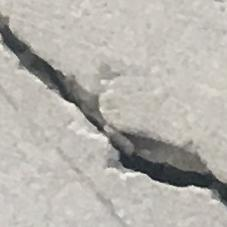

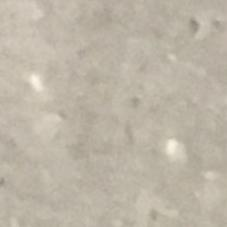

In [16]:
from PIL import Image
import os

positive = os.listdir("dataset_real/Positive")
negative = os.listdir("dataset_real/Negative")

imagen_positive = Image.open("dataset_real/Positive/" + positive[0])
imagen_negative = Image.open("dataset_real/Negative/" + negative[0])

display(imagen_positive)
display(imagen_negative)

In [17]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [18]:
train_ds, temp_ds = tf.keras.utils.image_dataset_from_directory(
    "dataset_real",
    validation_split=0.30,
    subset="both",
    seed=123,
    image_size=(224, 224),
    batch_size=32

)

Found 40000 files belonging to 2 classes.
Using 28000 files for training.
Using 12000 files for validation.


In [19]:
cantidad_batches = tf.data.experimental.cardinality(temp_ds)

test_ds = temp_ds.take(cantidad_batches // 2)
val_ds = temp_ds.skip(cantidad_batches // 2)

print("Listo")
print("Batches de validación:", tf.data.experimental.cardinality(val_ds).numpy())
print("Batches de test:", tf.data.experimental.cardinality(test_ds).numpy())

Listo
Batches de validación: 188
Batches de test: 187


In [20]:
print(train_ds.class_names)

['Negative', 'Positive']


In [21]:
imagenes, etiquetas = next(iter(train_ds))

print("Forma de las imágenes:", imagenes.shape)
print("Forma de las etiquetas:", etiquetas.shape)
print("Primeras etiquetas:", etiquetas[:10].numpy())

Forma de las imágenes: (32, 224, 224, 3)
Forma de las etiquetas: (32,)
Primeras etiquetas: [1 1 0 0 0 0 1 0 1 1]


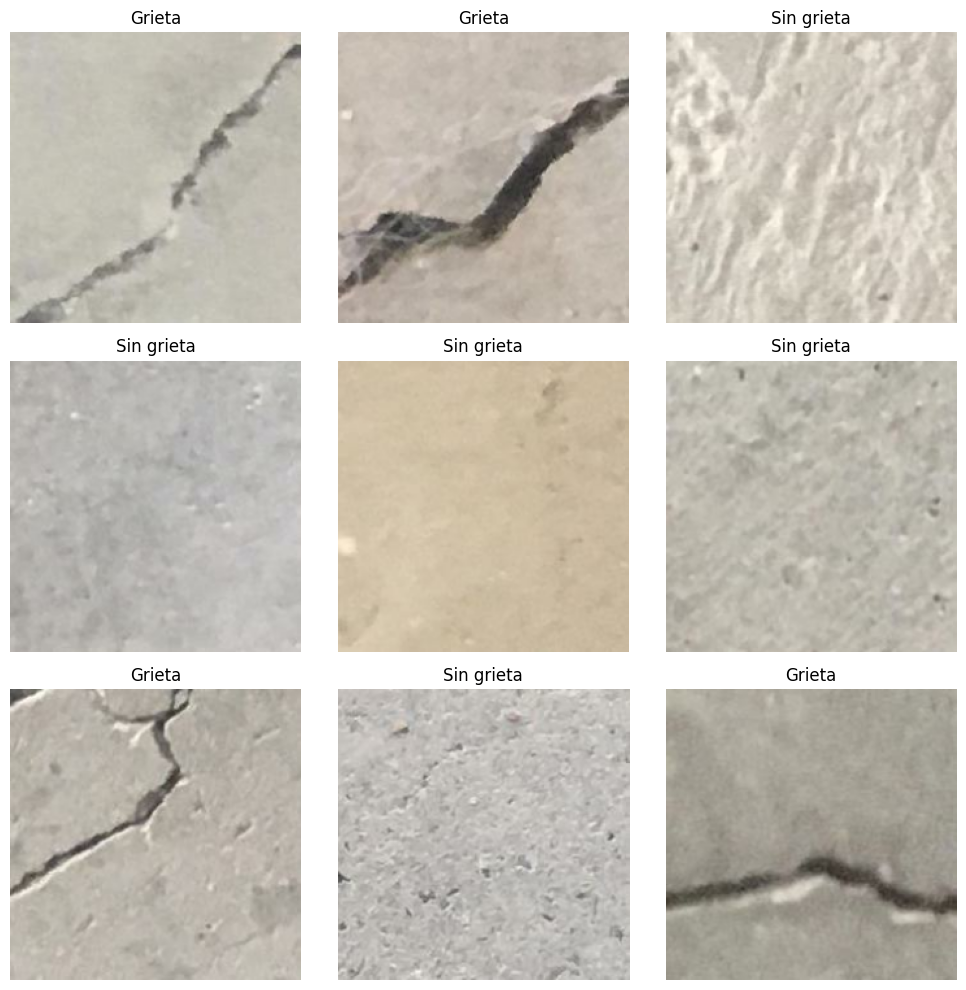

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for i in range(9):
    plt.subplot(3, 3, i + 1)
    plt.imshow(imagenes[i].numpy().astype("uint8"))

    if etiquetas[i] == 1:
        plt.title("Grieta")
    else:
        plt.title("Sin grieta")

    plt.axis("off")

plt.tight_layout()
plt.show()

In [23]:
AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.prefetch(buffer_size=AUTOTUNE)
test_ds = test_ds.prefetch(buffer_size=AUTOTUNE)

print("Datos preparados")

Datos preparados


In [24]:
base_model = tf.keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

print("MobileNetV2 cargada")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
MobileNetV2 cargada


In [25]:
base_model.trainable = False

print("Capas de MobileNetV2 congeladas")

Capas de MobileNetV2 congeladas


In [26]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
])

inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.applications.mobilenet_v2.preprocess_input(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dropout(0.2)(x)

outputs = tf.keras.layers.Dense(2, activation="softmax")(x)

model = tf.keras.Model(inputs, outputs)

print("Modelo creado")

Modelo creado


In [27]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Modelo compilado")

Modelo compilado


In [28]:
historial = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5
)

Epoch 1/5
875/875 ━━━━━━━━━━━━━━━━━━━━ 71s 72ms/step - accuracy: 0.9578 - loss: 0.1168 - val_accuracy: 0.9955 - val_loss: 0.0211
Epoch 2/5
875/875 ━━━━━━━━━━━━━━━━━━━━ 66s 75ms/step - accuracy: 0.9949 - loss: 0.0184 - val_accuracy: 0.9968 - val_loss: 0.0126
Epoch 3/5
875/875 ━━━━━━━━━━━━━━━━━━━━ 72s 83ms/step - accuracy: 0.9967 - loss: 0.0118 - val_accuracy: 0.9978 - val_loss: 0.0099
Epoch 4/5
875/875 ━━━━━━━━━━━━━━━━━━━━ 77s 77ms/step - accuracy: 0.9971 - loss: 0.0095 - val_accuracy: 0.9982 - val_loss: 0.0083
Epoch 5/5
875/875 ━━━━━━━━━━━━━━━━━━━━ 67s 77ms/step - accuracy: 0.9974 - loss: 0.0084 - val_accuracy: 0.9982 - val_loss: 0.0077


In [32]:

import os

ruta_modelo = "/content/drive/MyDrive/ProyectoGrietas/modelo_grietas.keras"

os.makedirs(os.path.dirname(ruta_modelo), exist_ok=True)

model.save(ruta_modelo)

print("Modelo guardado correctamente en Google Drive.")


Modelo guardado correctamente en Google Drive.


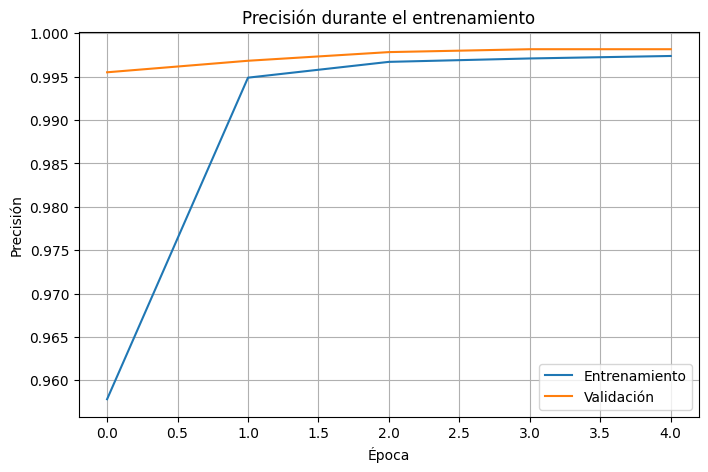

In [33]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(historial.history["accuracy"], label="Entrenamiento")
plt.plot(historial.history["val_accuracy"], label="Validación")

plt.xlabel("Época")
plt.ylabel("Precisión")
plt.title("Precisión durante el entrenamiento")
plt.legend()
plt.grid()

plt.show()

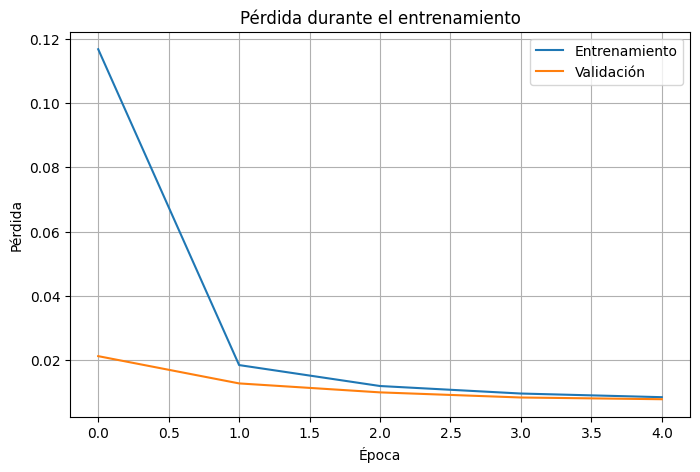

In [34]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(historial.history["loss"], label="Entrenamiento")
plt.plot(historial.history["val_loss"], label="Validación")

plt.xlabel("Época")
plt.ylabel("Pérdida")
plt.title("Pérdida durante el entrenamiento")
plt.legend()
plt.grid()

plt.show()

In [36]:
resultado_test = model.evaluate(test_ds)

print("Pérdida en test:", resultado_test[0])
print("Precisión en test:", resultado_test[1])

187/187 ━━━━━━━━━━━━━━━━━━━━ 11s 56ms/step - accuracy: 0.9972 - loss: 0.0078
Pérdida en test: 0.007830667309463024
Precisión en test: 0.9971590638160706


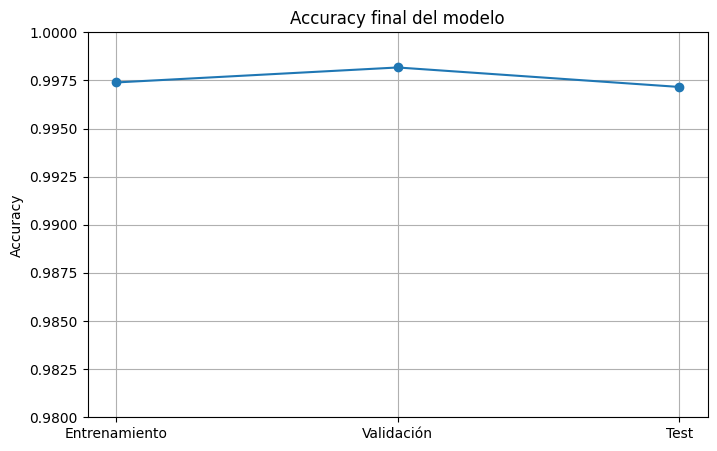

In [37]:
import matplotlib.pyplot as plt

accuracy_entrenamiento = historial.history["accuracy"][-1]
accuracy_validacion = historial.history["val_accuracy"][-1]
accuracy_test = resultado_test[1]

plt.figure(figsize=(8, 5))

plt.plot(
    ["Entrenamiento", "Validación", "Test"],
    [
        accuracy_entrenamiento,
        accuracy_validacion,
        accuracy_test
    ],
    marker="o"
)

plt.ylabel("Accuracy")
plt.title("Accuracy final del modelo")
plt.ylim(0.98, 1.00)
plt.grid()

plt.show()

In [38]:
import numpy as np

y_real = []
y_pred = []

for imagenes, etiquetas in test_ds:
    predicciones = model.predict(imagenes, verbose=0)

    y_real.extend(etiquetas.numpy())
    y_pred.extend(np.argmax(predicciones, axis=1))

y_real = np.array(y_real)
y_pred = np.array(y_pred)

print("Predicciones obtenidas")
print("Cantidad de imágenes:", len(y_real))

Predicciones obtenidas
Cantidad de imágenes: 5984


In [39]:
from google.colab import files

archivo = files.upload()

Saving gieta.jpeg to gieta.jpeg


In [40]:
imagen = Image.open("gieta.jpeg")


In [41]:
import numpy as np

matriz = np.array(imagen)

print(matriz.shape)

(1600, 1204, 3)


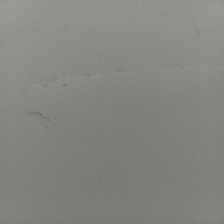

(224, 224)
RGB


In [42]:
imagen_redimensionada = imagen.resize((224, 224))
display(imagen_redimensionada)

print(imagen_redimensionada.size)
print(imagen_redimensionada.mode)

In [43]:
matriz_redimensionada = np.array(imagen_redimensionada)
print(matriz_redimensionada.shape)

(224, 224, 3)


In [44]:
import os

os.makedirs("dataset/grieta", exist_ok=True)
os.makedirs("dataset/sin_grieta", exist_ok=True)

print("Carpetas creadas")

Carpetas creadas


In [45]:
print(os.listdir("dataset"))

['grieta', 'sin_grieta']


In [46]:
imagen.save("dataset/grieta/ejemplo.jpg")

In [47]:
from PIL import Image
import numpy as np

imagen_nueva = Image.open("dataset/grieta/ejemplo.jpg")

print("Tamaño:", imagen_nueva.size)
print("Formato:", imagen_nueva.mode)

Tamaño: (1204, 1600)
Formato: RGB


In [48]:
imagen_nueva = imagen_nueva.resize((224, 224))

print("Nuevo tamaño:", imagen_nueva.size)

Nuevo tamaño: (224, 224)


In [49]:
imagen_array = np.array(imagen_nueva)

print("Forma:", imagen_array.shape)
print("Tipo de dato:", imagen_array.dtype)

Forma: (224, 224, 3)
Tipo de dato: uint8


In [50]:
imagen_entrada = np.expand_dims(imagen_array, axis=0)

print("Forma de entrada:", imagen_entrada.shape)

Forma de entrada: (1, 224, 224, 3)


In [51]:
prediccion = model.predict(imagen_entrada, verbose=0)

print(prediccion)

[[0.9959009  0.00409906]]


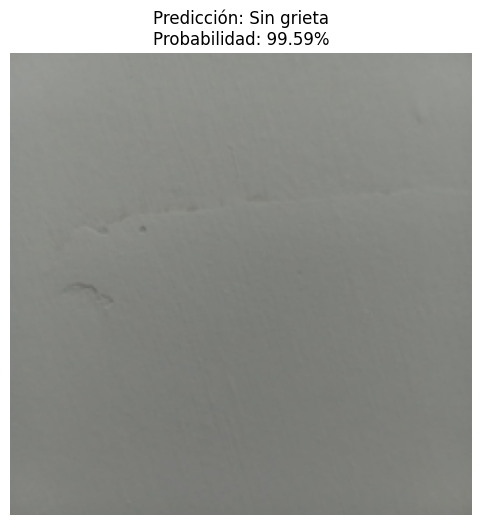

In [52]:
import matplotlib.pyplot as plt

clase = np.argmax(prediccion[0])

nombres_clases = ["Sin grieta", "Grieta"]
probabilidad = prediccion[0][clase]

plt.figure(figsize=(6, 6))
plt.imshow(imagen_nueva)
plt.axis("off")

plt.title(
    f"Predicción: {nombres_clases[clase]}\n"
    f"Probabilidad: {probabilidad * 100:.2f}%"
)

plt.show()

In [ ]:
from google.colab import files

archivo = files.upload()

Saving inclinacion_2.jpeg to inclinacion_2.jpeg


Probabilidad de sin grieta: 75.40%
Probabilidad de grieta: 24.60%
Predicción: Sin grieta


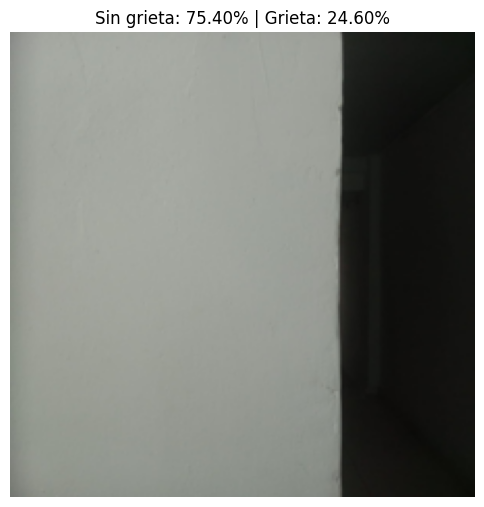

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen
imagen_prueba = Image.open("inclinacion_2.jpeg")

# Redimensionar
imagen_prueba = imagen_prueba.resize((224, 224))

# Convertir a NumPy y agregar dimensión de lote
imagen_prueba_np = np.array(imagen_prueba)
imagen_prueba_np = np.expand_dims(imagen_prueba_np, axis=0)

# Predicción
prediccion = model.predict(imagen_prueba_np, verbose=0)

# Probabilidades
prob_sin_grieta = prediccion[0][0] * 100
prob_grieta = prediccion[0][1] * 100

# Mostrar resultados
print(f"Probabilidad de sin grieta: {prob_sin_grieta:.2f}%")
print(f"Probabilidad de grieta: {prob_grieta:.2f}%")

if prob_grieta > prob_sin_grieta:
    print("Predicción: Grieta")
else:
    print("Predicción: Sin grieta")

# Mostrar imagen
plt.figure(figsize=(6, 8))
plt.imshow(imagen_prueba)
plt.axis("off")
plt.title(
    f"Sin grieta: {prob_sin_grieta:.2f}% | "
    f"Grieta: {prob_grieta:.2f}%"
)
plt.show()

Forma de la imagen: (1600, 1204, 3)


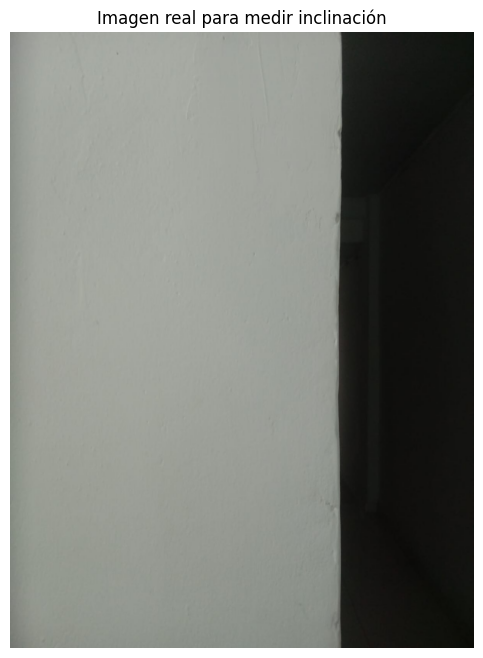

In [ ]:
import cv2
import matplotlib.pyplot as plt

imagen_inclinacion = cv2.imread("inclinacion_2.jpeg")

print("Forma de la imagen:", imagen_inclinacion.shape)

plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(imagen_inclinacion, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Imagen real para medir inclinación")
plt.show()

Forma en escala de grises: (1600, 1204)


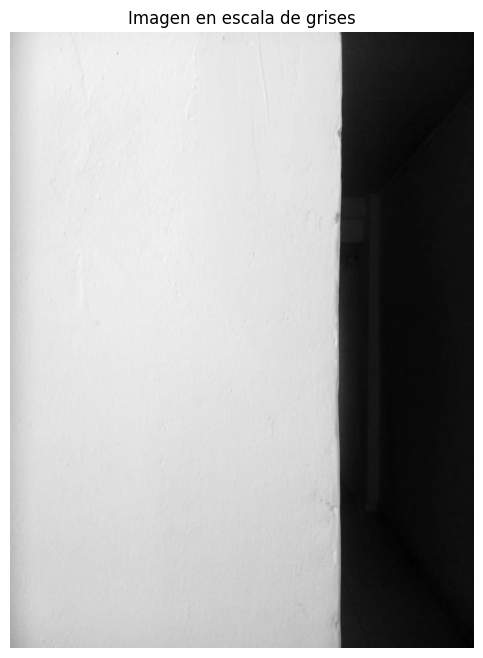

In [ ]:
gris_inclinacion = cv2.cvtColor(
    imagen_inclinacion,
    cv2.COLOR_BGR2GRAY
)

print("Forma en escala de grises:", gris_inclinacion.shape)

plt.figure(figsize=(6, 8))
plt.imshow(gris_inclinacion, cmap="gray")
plt.axis("off")
plt.title("Imagen en escala de grises")
plt.show()

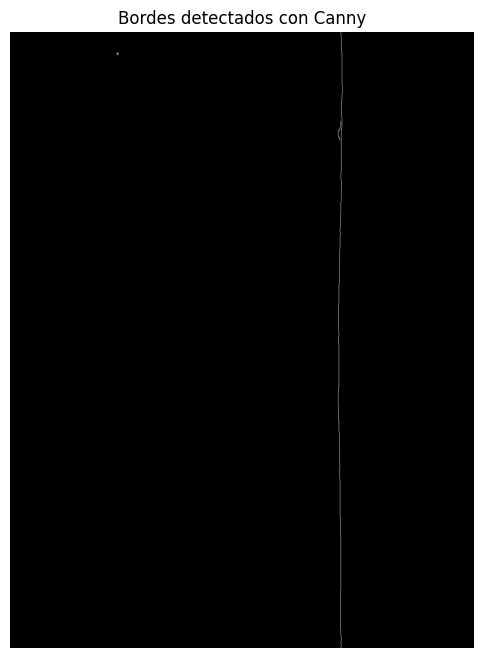

In [ ]:
bordes_inclinacion = cv2.Canny(
    gris_inclinacion,
    50,
    150
)

plt.figure(figsize=(6, 8))
plt.imshow(bordes_inclinacion, cmap="gray")
plt.axis("off")
plt.title("Bordes detectados con Canny")
plt.show()

In [ ]:
lineas_inclinacion = cv2.HoughLinesP(
    bordes_inclinacion,
    1,
    np.pi / 180,
    threshold=50,
    minLineLength=100,
    maxLineGap=20
)

print("Líneas detectadas:", len(lineas_inclinacion))

Líneas detectadas: 8


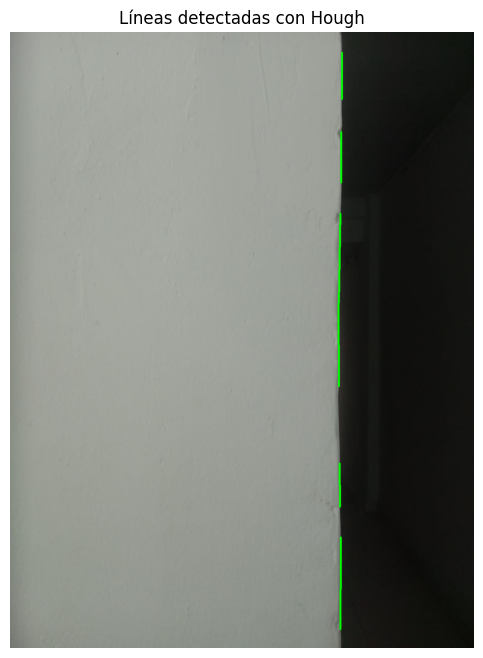

In [ ]:
imagen_lineas = imagen_inclinacion.copy()

for linea in lineas_inclinacion:
    x1, y1, x2, y2 = linea[0]

    cv2.line(
        imagen_lineas,
        (x1, y1),
        (x2, y2),
        (0, 255, 0),
        3
    )

plt.figure(figsize=(6,8))
plt.imshow(cv2.cvtColor(imagen_lineas, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title("Líneas detectadas con Hough")
plt.show()

In [ ]:
import math
import numpy as np

angulos = []

for linea in lineas_inclinacion:
    x1, y1, x2, y2 = linea[0]

    angulo = math.degrees(
        math.atan2(y2 - y1, x2 - x1)
    )

    angulos.append(angulo)

    print(f"Línea: {angulo:.2f}°")

Línea: -89.01°
Línea: 89.49°
Línea: -90.00°
Línea: -90.00°
Línea: -90.00°
Línea: -90.00°
Línea: -90.00°
Línea: -90.00°


In [ ]:
inclinaciones = []

for angulo in angulos:
    inclinacion = abs(90 - abs(angulo))
    inclinaciones.append(inclinacion)

    print(f"Inclinación: {inclinacion:.2f}°")

Inclinación: 0.99°
Inclinación: 0.51°
Inclinación: 0.00°
Inclinación: 0.00°
Inclinación: 0.00°
Inclinación: 0.00°
Inclinación: 0.00°
Inclinación: 0.00°


In [ ]:
promedio_inclinacion = np.mean(inclinaciones)

print(f"Inclinación promedio: {promedio_inclinacion:.2f}°")

Inclinación promedio: 0.19°


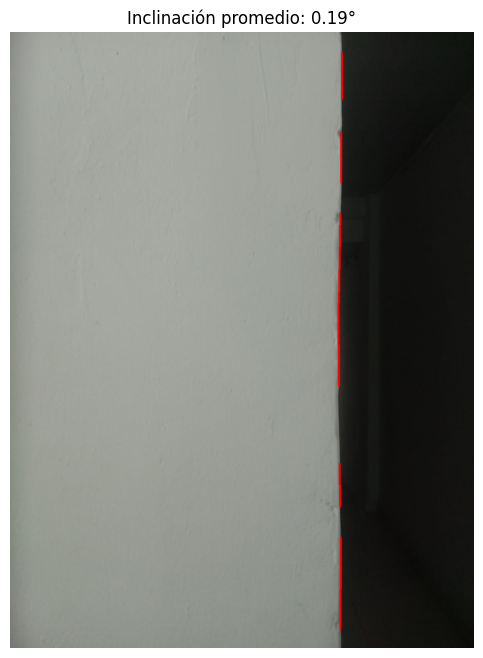

In [ ]:
imagen_resultado = imagen_inclinacion.copy()

for linea in lineas_inclinacion:
    x1, y1, x2, y2 = linea[0]

    cv2.line(
        imagen_resultado,
        (x1, y1),
        (x2, y2),
        (0, 0, 255),
        3
    )

plt.figure(figsize=(6, 8))
plt.imshow(cv2.cvtColor(imagen_resultado, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.title(f"Inclinación promedio: {promedio_inclinacion:.2f}°")
plt.show()

Probabilidad de sin grieta: 75.40%
Probabilidad de grieta: 24.60%
Predicción: Sin grieta


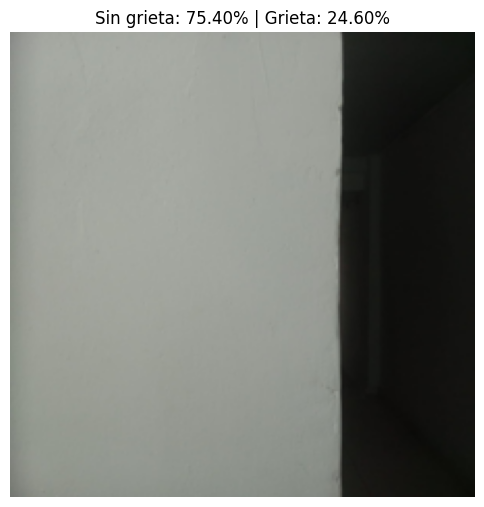

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

# Cargar imagen
imagen_prueba = Image.open("inclinacion_2.jpeg")

# Redimensionar
imagen_prueba = imagen_prueba.resize((224, 224))

# Convertir a NumPy y agregar dimensión de lote
imagen_prueba_np = np.array(imagen_prueba)
imagen_prueba_np = np.expand_dims(imagen_prueba_np, axis=0)

# Predicción
prediccion = model.predict(imagen_prueba_np, verbose=0)

# Probabilidades
prob_sin_grieta = prediccion[0][0] * 100
prob_grieta = prediccion[0][1] * 100

# Mostrar resultados
print(f"Probabilidad de sin grieta: {prob_sin_grieta:.2f}%")
print(f"Probabilidad de grieta: {prob_grieta:.2f}%")

if prob_grieta > prob_sin_grieta:
    print("Predicción: Grieta")
else:
    print("Predicción: Sin grieta")

# Mostrar imagen
plt.figure(figsize=(6, 8))
plt.imshow(imagen_prueba)
plt.axis("off")
plt.title(
    f"Sin grieta: {prob_sin_grieta:.2f}% | "
    f"Grieta: {prob_grieta:.2f}%"
)
plt.show()